In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({'font.size':20})
import os
from scipy.io import loadmat

import sys
sys.path.append('/home/ks2823/SerialDilutionModel/src/')

from SerialDilutionModels import LatentAssemblyModel
import copy
from glob import glob
import torch
import scipy as sp

## Explore model behavior

In [2]:
model = LatentAssemblyModel(125, 3, 3)
model.load_state_dict(torch.load('../Data/Pollard_model.pth', weights_only=True))
model.eval()

LatentAssemblyModel()

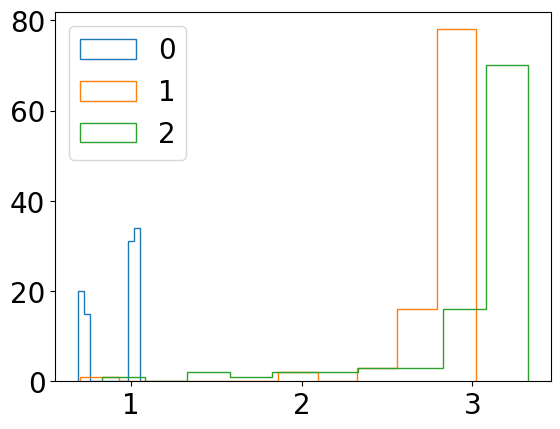

In [ ]:
def sample_simplex_torch(n, num_samples=1, device='cpu', dtype=torch.float32):
    """
    Uniformly samples from an n-dimensional simplex using PyTorch distributions.
    """
    # Create the base distribution on the target device
    exp_dist = torch.distributions.Exponential(rate=torch.tensor([1.0], device=device, dtype=dtype))
    
    # Sample a matrix of shape (num_samples, n)
    raw_samples = exp_dist.sample((num_samples, n)).squeeze(-1)
    
    # Normalize along the columns so each row sums to 1
    return raw_samples / raw_samples.sum(dim=-1, keepdim=True)

samples = sample_simplex_torch(125, 100)

with torch.no_grad():
    entropy_list = []
    for sample in samples:
        entropy_sub_list = []
        for cond in range(3):
            entropy = sp.stats.entropy(model.find_steady_state(sample, cond)[0])
            entropy_sub_list.append(entropy)
        entropy_list.append(entropy_sub_list)

entropy_list = np.array(entropy_list)

for i in range(3):
    plt.hist(entropy_list[:, i], histtype='step', label=i)
plt.legend()
plt.xlabel('Entropy')
plt.show()

In [5]:
with torch.no_grad():
    env_growth_factor_list = []
    for cond in range(3):
        env_growth_factor = -model.a[cond] @ model.Theta.T
        sort_idxs = np.argsort(env_growth_factor)
        descending_sort_idxs = sort_idxs.flip(dims=[0]) 
        env_growth_factor_list.append(env_growth_factor[descending_sort_idxs])

env_growth_factor_list = np.array(env_growth_factor_list)

In [7]:
env_growth_factor_list[0]

array([ 3.3778658e+00,  2.5111818e+00,  2.2738276e+00,  1.9579220e+00,
        1.9518838e+00,  1.8459147e+00,  1.8230276e+00,  1.7537886e+00,
        1.7406315e+00,  1.7008836e+00,  1.6841520e+00,  1.6162316e+00,
        1.6159286e+00,  1.5745271e+00,  1.5199697e+00,  1.4876109e+00,
        1.4098243e+00,  1.4050711e+00,  1.3934891e+00,  1.3410143e+00,
        1.3150997e+00,  1.3130542e+00,  1.2254636e+00,  1.2014606e+00,
        1.1868817e+00,  1.1586891e+00,  1.1233985e+00,  1.0167801e+00,
        9.8633224e-01,  9.3809891e-01,  8.3175719e-01,  8.1667382e-01,
        8.0224741e-01,  7.6873875e-01,  7.5968999e-01,  7.5084543e-01,
        7.2792339e-01,  7.1435279e-01,  6.9218588e-01,  6.4690965e-01,
        6.1603558e-01,  6.1218125e-01,  5.8372748e-01,  5.5685043e-01,
        5.5084836e-01,  5.0256401e-01,  4.7240916e-01,  4.4547272e-01,
        4.3747392e-01,  4.2324549e-01,  2.5005278e-01,  2.2637619e-01,
        1.0767877e-01,  9.9220783e-02,  9.1134205e-02,  7.7900067e-02,
      

In [8]:
env_growth_factor_list[2]

array([ 2.5206797e+00,  1.9461945e+00,  1.8797508e+00,  1.6311065e+00,
        1.6179860e+00,  1.5457091e+00,  1.2233998e+00,  1.1556953e+00,
        1.0982926e+00,  8.9238864e-01,  8.5361797e-01,  7.8199166e-01,
        6.4145148e-01,  6.2018484e-01,  5.8787251e-01,  5.5201483e-01,
        5.3888559e-01,  4.9909389e-01,  4.3147546e-01,  4.3076974e-01,
        3.9532802e-01,  3.6519831e-01,  3.4463048e-01,  3.1931058e-01,
        2.2656086e-01,  2.1589546e-01,  1.9970205e-01,  1.1767603e-01,
        7.2959863e-02,  6.6590786e-02,  2.0949630e-02,  2.3768591e-03,
       -4.7660828e-02, -4.8203088e-02, -7.2299428e-02, -9.0911478e-02,
       -1.1513152e-01, -1.1832739e-01, -1.2035461e-01, -1.7783421e-01,
       -2.1099314e-01, -2.1921559e-01, -2.1944204e-01, -2.9615727e-01,
       -3.0198398e-01, -3.0929929e-01, -3.1484219e-01, -3.3938864e-01,
       -3.6674765e-01, -3.7521434e-01, -4.2618242e-01, -4.2832398e-01,
       -4.4241840e-01, -4.4983155e-01, -4.9307969e-01, -5.7260162e-01,
      

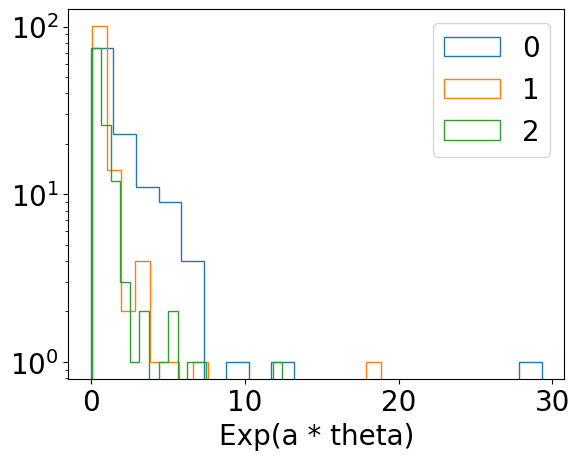

In [23]:
for i in range(3):
    plt.hist(np.exp(env_growth_factor_list[i]), histtype='step', label=i, bins=20)

plt.xlabel('Exp(a * theta)')
plt.yscale('log')
plt.legend()
plt.show()

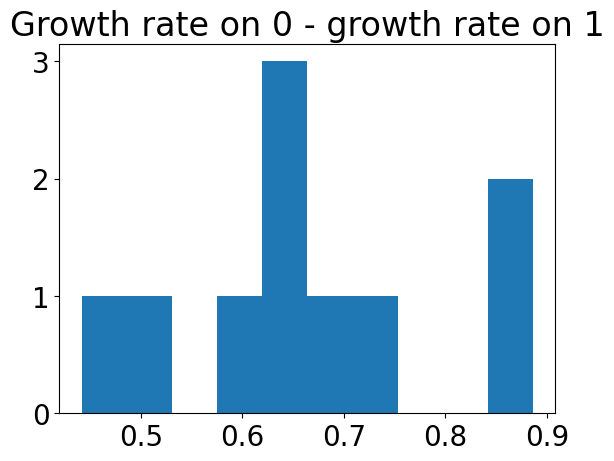

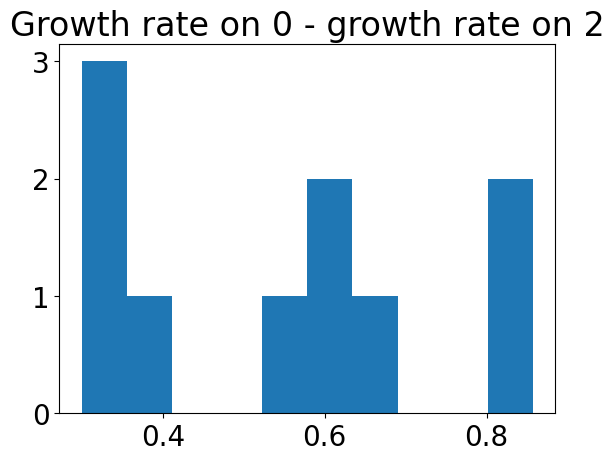

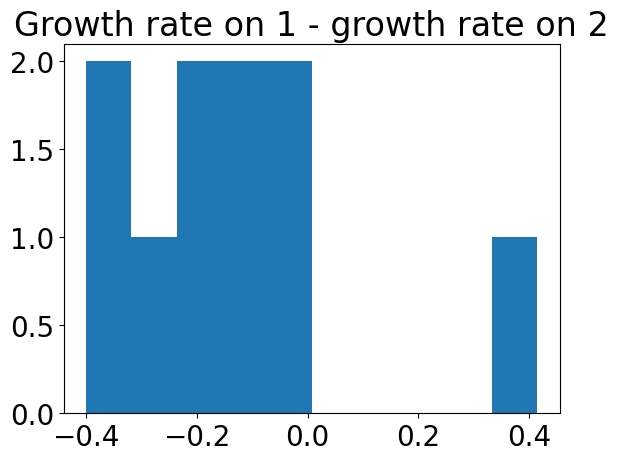

In [16]:
for i in range(3):
    for j in range(i+1, 3):
        plt.hist(env_growth_factor_list[i][:10] - env_growth_factor_list[j][:10])
        plt.title(f'Growth rate on {i} - growth rate on {j}')
        plt.show()

## Explore data

In [20]:
def load_condition_data(csv_path, condition):
    """
    Parses the Jin et al. SupplementaryDataS2.csv file and extracts all sequential
    passage transitions (in, out) for a single specified condition.
    """
    print(f"Loading experimental data from {csv_path} for condition: '{condition}'...")
    df = pd.read_csv(csv_path)
    
    # 1. Clean replicate names to group technical replicates
    df['bio_rep'] = df['replicate'].astype(str).str[:2]
    
    # 2. Average over technical replicates
    df_avg = df.groupby(['sampleType', 'passage', 'bio_rep', 'Strain_Name'])['Read_Fraction'].mean().reset_index()
    
    # 3. Pivot so each row is a sample and each column is a strain
    pivot = df_avg.pivot_table(index=['sampleType', 'bio_rep', 'passage'], 
                               columns='Strain_Name', values='Read_Fraction', fill_value=0.0)
    
    # 4. Normalize relative abundances
    pivot = pivot.div(pivot.sum(axis=1), axis=0)
    
    strains = pivot.columns.tolist()
    N = len(strains)
    
    if 'inoculum' in pivot.index.get_level_values('sampleType'):
        inoculum_data = pivot.xs('inoculum', level='sampleType')
    else:
        inoculum_data = None
        
    # Maps conditions to indices (keeps compatibility if your model relies on specific condition IDs)
    cond_map = {'no carriers': 0, 'plain-agar carriers': 1, 'mucin-agar carriers': 2}
    if condition not in cond_map:
        # Dynamically assign an index if a novel condition string is passed
        cond_map[condition] = len(cond_map)
    c_idx = cond_map[condition]
    
    # Verify condition exists in dataset
    available_conditions = pivot.index.get_level_values('sampleType').unique()
    if condition not in available_conditions:
        raise ValueError(f"Condition '{condition}' not found in dataset. Available conditions: {list(available_conditions)}")
            
    x_in, x_out, c_vals = [], [], []
    
    cond_data = pivot.xs(condition, level='sampleType')
    for rep in cond_data.index.get_level_values('bio_rep').unique():
        rep_df = cond_data.xs(rep, level='bio_rep')
        passages = sorted(rep_df.index.tolist()) 
        
        # Extract Inoculum (P0) -> P1 transition
        if inoculum_data is not None and 'P1' in passages:
            if rep in inoculum_data.index.get_level_values('bio_rep'):
                p0 = inoculum_data.xs(rep, level='bio_rep').loc['P0'].values
            else:
                p0 = inoculum_data.mean(axis=0).values
            p_next_vals = rep_df.loc['P1'].values
            
            x_in.append(p0)
            x_out.append(p_next_vals)
            c_vals.append(c_idx)
                
        # Extract all Inter-passage transitions (P1->P2, P2->P3, etc.) without splitting
        for i in range(len(passages) - 1):
            p_cur, p_next = passages[i], passages[i+1]
            cur_vals, next_vals = rep_df.loc[p_cur].values, rep_df.loc[p_next].values
            
            x_in.append(cur_vals)
            x_out.append(next_vals)
            c_vals.append(c_idx)

    # Convert to PyTorch Tensors
    t_in = torch.tensor(np.array(x_in), dtype=torch.float32)
    t_out = torch.tensor(np.array(x_out), dtype=torch.float32)
    t_c = torch.tensor(np.array(c_vals), dtype=torch.long)
    
    print(f"Data Extraction Complete for '{condition}':")
    print(f" - Extracted {len(t_in)} total transitions across {N} strains.")
    
    return t_in, t_out, t_c, N, strains

In [23]:
condition = 'mucin-agar carriers'
csv_path = '../Data/SupplementaryDataS2.csv'

X_train, y_train, c_train, N, strains = load_condition_data(csv_path=csv_path, condition=condition)

Loading experimental data from ../Data/SupplementaryDataS2.csv for condition: 'mucin-agar carriers'...
Data Extraction Complete for 'mucin-agar carriers':
 - Extracted 18 total transitions across 125 strains.


In [26]:
X_train.shape

torch.Size([18, 125])